In [15]:
!pip install ultralytics paddleocr paddlepaddle opencv-python

In [16]:
import cv2
from ultralytics import YOLO
from paddleocr import PaddleOCR
from google.colab.patches import cv2_imshow

In [17]:
# Load Models
vehicle_model = YOLO("yolov8n.pt")
violation_model = YOLO("violation_det.pt")

Successfully loaded custom violation model!



image 1/1 /content/test.jpg: 384x640 9 persons, 4 cars, 5 motorcycles, 423.2ms
Speed: 13.9ms preprocess, 423.2ms inference, 33.7ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 /content/test.jpg: 256x416 4 without_helmets, 4 riders, 2 number_plates, 87.1ms
Speed: 2.1ms preprocess, 87.1ms inference, 0.9ms postprocess per image at shape (1, 3, 256, 416)
Violation Detected: No Helmet (Conf: 0.95)
Violation Detected: No Helmet (Conf: 0.91)
Violation Detected: No Helmet (Conf: 0.87)
Violation Detected: No Helmet (Conf: 0.65)


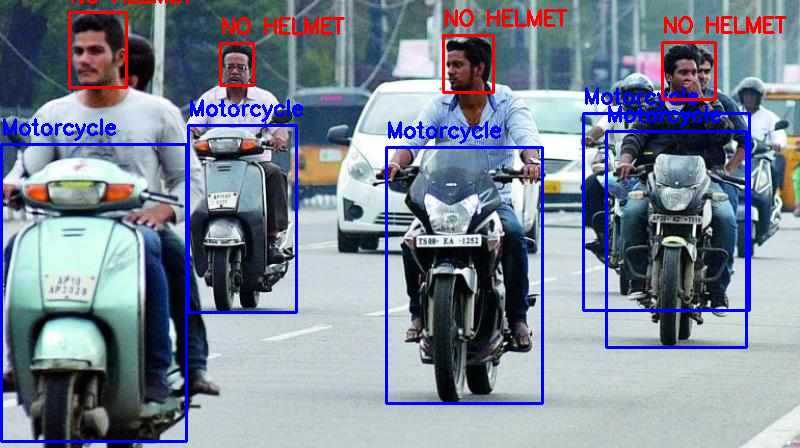

Done!


In [18]:
# OCR
ocr = PaddleOCR(use_angle_cls=True, lang='en')

# Read Image
image_path = "test.jpg"
img = cv2.imread(image_path)

# Run Detection
vehicle_results = vehicle_model(image_path)[0]
violation_results = violation_model(image_path)[0]

# COCO Motorcycle Class ID
MOTORCYCLE = 3

vehicles = []
plates = []

# Vehicle Detection
for box in vehicle_results.boxes:
    cls = int(box.cls[0])
    conf = float(box.conf[0])

    if conf < 0.3:
        continue

    x1,y1,x2,y2 = map(int, box.xyxy[0])

    if cls == MOTORCYCLE:
        vehicles.append((x1,y1,x2,y2))

        cv2.rectangle(img,(x1,y1),(x2,y2),(255,0,0),2)
        cv2.putText(img,"Motorcycle",(x1,y1-10),
                    cv2.FONT_HERSHEY_SIMPLEX,0.7,(255,0,0),2)

# Custom Model Classes
WITH_HELMET = 0
WITHOUT_HELMET = 1
RIDER = 2
NUMBER_PLATE = 3

# Violation Detection
for box in violation_results.boxes:

    cls = int(box.cls[0])
    conf = float(box.conf[0])

    if conf < 0.3:
        continue

    x1,y1,x2,y2 = map(int, box.xyxy[0])

    # No Helmet
    if cls == WITHOUT_HELMET:

        cv2.rectangle(img,(x1,y1),(x2,y2),(0,0,255),2)
        cv2.putText(img,"NO HELMET",(x1,y1-10),
                    cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,0,255),2)

        print("Violation: No Helmet")

    # Number Plate OCR
    elif cls == NUMBER_PLATE:

        crop = img[y1:y2,x1:x2]

        try:
            result = ocr.ocr(crop)

            plate_text = ""

            if result and result[0]:
                for line in result[0]:
                    plate_text += line[1][0]

            print("Plate:", plate_text)

            cv2.rectangle(img,(x1,y1),(x2,y2),(255,0,255),2)
            cv2.putText(img,plate_text,(x1,y1-10),
                        cv2.FONT_HERSHEY_SIMPLEX,0.7,(255,0,255),2)

        except:
            pass

# Show Result
cv2_imshow(img)
cv2.imwrite("result.jpg", img)

print("Done!")